# Oscar 1927–2024: cinco perguntas estratégicas

Este notebook consome o pacote `projeto1_c11`. A lógica de cada pergunta vive em `src/projeto1_c11/questions/`; aqui entram a narrativa, as tabelas e os gráficos do pitch.

Dataset: [`unanimad/the-oscar-award`](https://www.kaggle.com/datasets/unanimad/the-oscar-award).

## 0. Carga e descoberta

In [1]:
from projeto1_c11.data import load_oscars
from projeto1_c11.plotting import apply_style, save_fig
from projeto1_c11.questions import (
    q01_conversao,
    q02_precursoras,
    q03_evolucao,
    q04_eficiencia,
    q05_concentracao,
)

apply_style()
df = load_oscars()
df.head()

,year_film,year_ceremony,ceremony,category,canon_category,name,film,winner,category_canon,is_best_picture,is_honorary,decade
0,1927,1928,1,ACTOR,ACTOR IN A LEADING ROLE,Richard Barthelmess,The Noose,False,ACTOR IN A LEADING ROLE,False,False,1920
1,1927,1928,1,ACTOR,ACTOR IN A LEADING ROLE,Richard Barthelmess,The Patent Leather Kid,False,ACTOR IN A LEADING ROLE,False,False,1920
2,1927,1928,1,ACTOR,ACTOR IN A LEADING ROLE,Emil Jannings,The Last Command,True,ACTOR IN A LEADING ROLE,False,False,1920
3,1927,1928,1,ACTOR,ACTOR IN A LEADING ROLE,Emil Jannings,The Way of All Flesh,True,ACTOR IN A LEADING ROLE,False,False,1920
4,1927,1928,1,ACTRESS,ACTRESS IN A LEADING ROLE,Louise Dresser,A Ship Comes In,False,ACTRESS IN A LEADING ROLE,False,False,1920


In [2]:
print(f'linhas={len(df):,}  colunas={df.shape[1]}')
print(df.dtypes)
df.isna().sum().to_frame('n_ausentes')

linhas=11,240  colunas=12
year_film            int64
year_ceremony        int64
ceremony             int64
category            string
canon_category         str
name                string
film                string
winner                bool
category_canon      string
is_best_picture    boolean
is_honorary           bool
decade               int64
dtype: object


,n_ausentes
year_film,0
year_ceremony,0
ceremony,0
category,0
canon_category,0
name,12
film,363
winner,0
category_canon,0
is_best_picture,0


In [3]:
n_raw = df['category'].nunique()
n_canon = df['category_canon'].nunique()
print(f'categorias originais={n_raw}  após unificar Melhor Filme={n_canon}')

remakes = (
    df.dropna(subset=['film'])
    .groupby('film')['year_ceremony']
    .nunique()
    .loc[lambda s: s > 1]
    .sort_values(ascending=False)
)
print(f'títulos em mais de uma cerimônia={len(remakes)}')
remakes.head(10).to_frame('n_cerimonias')

categorias originais=120  após unificar Melhor Filme=59
títulos em mais de uma cerimônia=111


,n_cerimonias
film,
A Star Is Born,4
Little Women,4
Emma,3
Hamlet,3
Alice in Wonderland,2
A Farewell to Arms,2
A Place in the Sun,2
Back Street,2
Beauty and the Beast,2


### Três desafios da etapa de Descoberta (Slide 4)

1. **Padronização de categorias históricas.** Melhor Filme já se chamou *Outstanding Picture*, *Outstanding Production*, *Outstanding Motion Picture* e *Best Motion Picture*. Sem unificar esses nomes, qualquer análise da categoria principal parte o século no meio.
2. **Valores ausentes.** Prêmios honorários e especiais frequentemente vêm sem `film` (e às vezes sem `name` padronizado). Por isso as perguntas de filme/profissional excluem `is_honorary` e descartam nulos da chave.
3. **Filmes homônimos.** Remakes compartilham o título; a chave de filme é sempre `['film', 'year_ceremony']`, nunca só o nome.

## Q1. Volume de indicações e conversão em vitórias

Qual é a relação entre o volume de indicações de um filme e sua taxa de conversão em vitórias? Existe um ponto de virada?

**Como lemos:** cada ponto é um filme-cerimônia. O painel da direita mostra a taxa média de vitória por faixa de indicações — o candidato a "ponto de virada" para o investimento em campanha FYC.

In [4]:
print(q01_conversao.QUESTION)
q01 = q01_conversao.compute(df)
display(q01_conversao.correlations(q01).to_frame('correlação'))
display(q01_conversao.conversion_by_bin(q01))
q01.head(10)

Qual é a relação entre o volume de indicações de um filme e sua taxa de conversão em vitórias? Existe um ponto de virada?


,correlação
pearson,0.689795
spearman,0.433211


,nomination_bin,n_films,mean_wins,mean_win_rate
0,1,3543,0.158905,0.158905
1,2–3,903,0.301218,0.128092
2,4–6,501,0.938124,0.193114
3,7–9,207,2.154589,0.275372
4,10+,107,4.261682,0.380712


,film,year_ceremony,nominations,wins,year_film,win_rate
0,Titanic,1998,14,11,1997,0.785714
1,Ben-Hur,1960,12,11,1959,0.916667
2,The Lord of the Rings: The Return of the King,2004,11,11,2003,1.000000
3,West Side Story,1962,11,10,1961,0.909091
4,The English Patient,1997,12,9,1996,0.750000
5,Gigi,1959,9,9,1958,1.000000
6,The Last Emperor,1988,9,9,1987,1.000000
7,From Here to Eternity,1954,13,8,1953,0.615385
8,Gone with the Wind,1940,13,8,1939,0.615385
9,My Fair Lady,1965,12,8,1964,0.666667


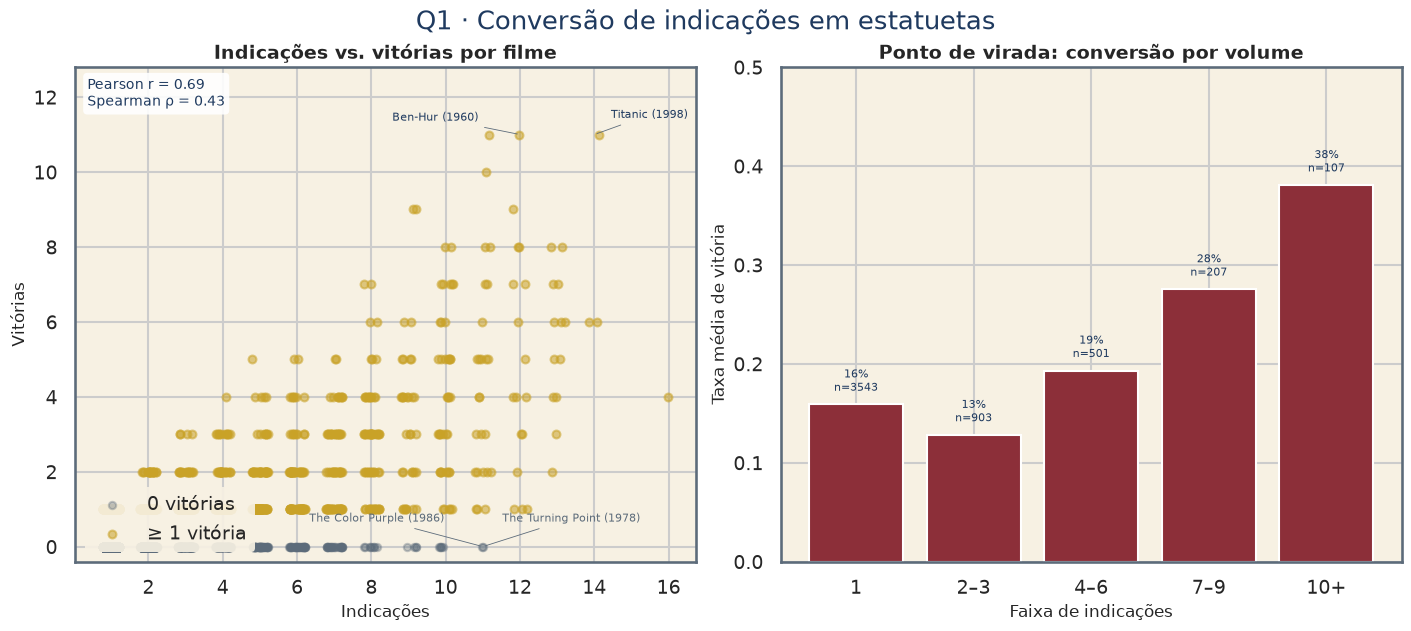

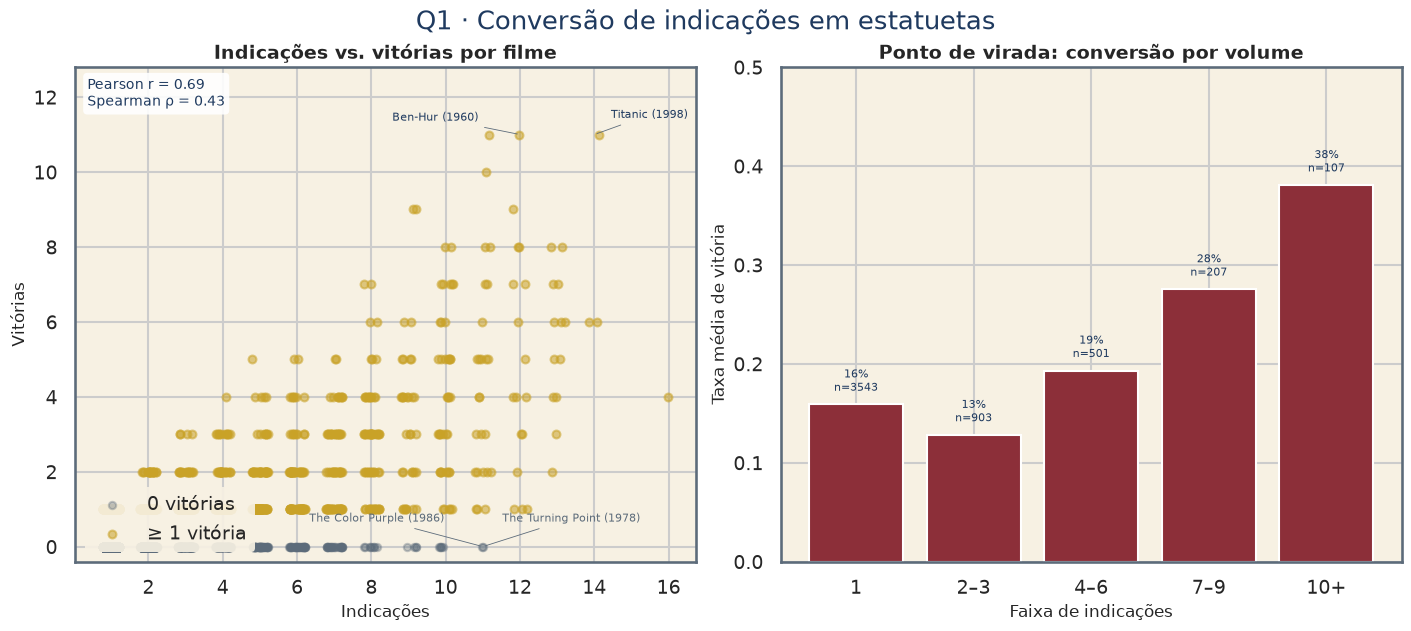

In [5]:
fig = q01_conversao.plot(q01)
save_fig(fig, q01_conversao.SLUG)
fig

**Insight.** Mais indicações acompanham mais vitórias (correlação positiva), mas a conversão não é linear: o salto de faixa costuma aparecer nas faixas altas, enquanto o extremo direito também concentra os maiores esnobados (muitas indicações e zero estatuetas). Para o estúdio, pulverizar campanha em dezenas de categorias não garante a noite — e pode produzir o pior dos mundos: visibilidade máxima sem a foto da estatueta.

## Q2. Categorias precursoras de Melhor Filme

Para um filme vencer Melhor Filme, quais outras categorias historicamente têm a maior correlação de vitória conjunta?

Universo: filmes **indicados** a Melhor Filme (não a indústria inteira). Para cada categoria X: `P(venceu X | venceu BP)`, `P(venceu BP | venceu X)` e o coeficiente φ entre as duas binárias.

In [6]:
print(q02_precursoras.QUESTION)
q02 = q02_precursoras.compute(df)
q02.head(15)

Para um filme vencer Melhor Filme, quais outras categorias historicamente têm a maior correlação de vitória conjunta?


,category,n_films,n_bp_winners,n_won_x,n_won_both,p_x_given_bp,p_bp_given_x,phi
0,DIRECTING,621,98,96,71,0.724490,0.739583,0.682398
1,WRITING (ADAPTED SCREENPLAY),621,98,95,44,0.448980,0.463158,0.355952
2,FILM EDITING,621,98,78,38,0.387755,0.487179,0.342420
3,ACTOR IN A LEADING ROLE,621,98,78,28,0.285714,0.358974,0.209135
4,SOUND MIXING,621,98,53,21,0.214286,0.396226,0.199769
5,ACTOR IN A SUPPORTING ROLE,621,98,53,21,0.214286,0.396226,0.199769
6,CINEMATOGRAPHY (COLOR),621,98,17,9,0.091837,0.529412,0.171006
7,ART DIRECTION,621,98,55,19,0.193878,0.345455,0.160449
8,WRITING (ORIGINAL SCREENPLAY),621,98,60,20,0.204082,0.333333,0.157455
9,COSTUME DESIGN,621,98,33,13,0.132653,0.393939,0.153443


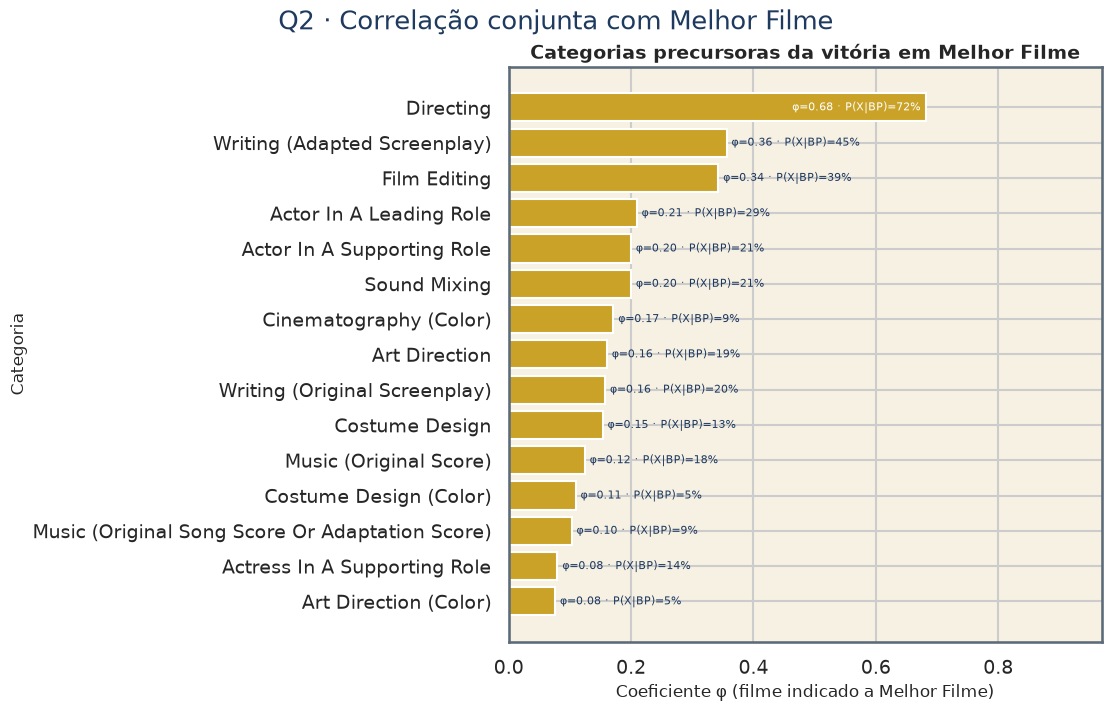

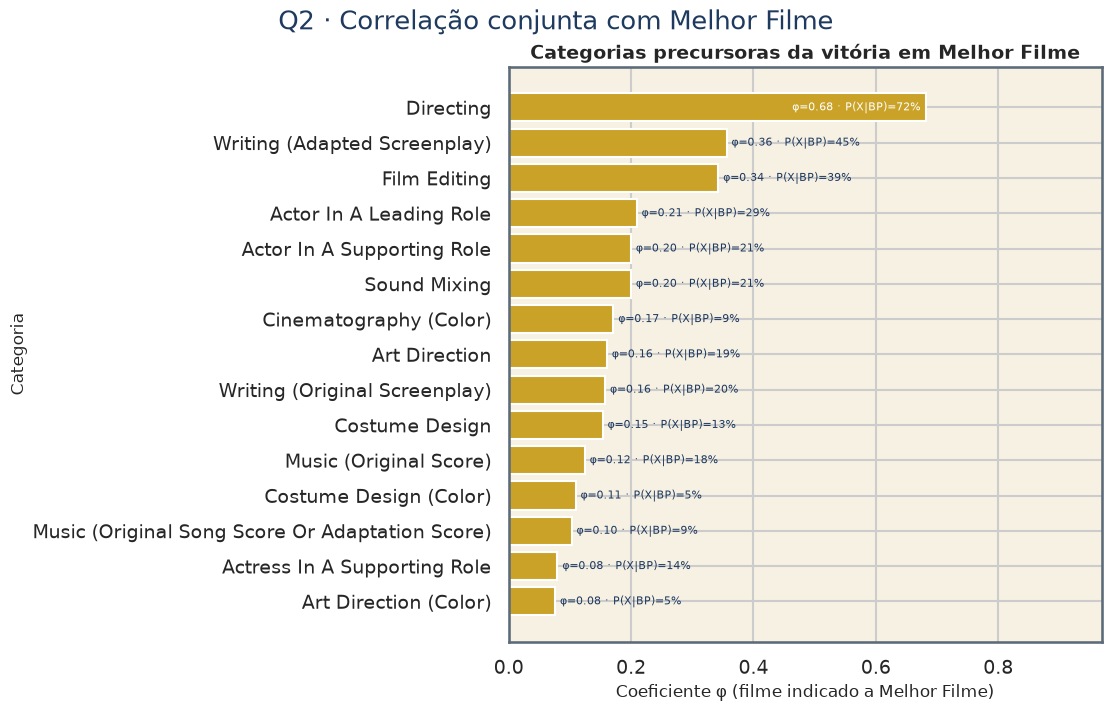

In [7]:
fig = q02_precursoras.plot(q02)
save_fig(fig, q02_precursoras.SLUG)
fig

**Insight.** Direção, montagem e roteiro original/adaptado costumam ser o termômetro real da noite: um filme que leva essas categorias raramente é só "indicado de volume". Produtoras e apostadores devem tratar essas estatuetas como precursoras, não como prêmios consolação.

## Q3. Evolução da Academia por década

Como o perfil da Academia evoluiu ao longo das décadas em termos de diversidade de categorias e quantidade de prêmios distribuídos por cerimônia?

In [10]:
print(q03_evolucao.QUESTION)
q03 = q03_evolucao.compute(df)
q03

Como o perfil da Academia evoluiu ao longo das décadas em termos de diversidade de categorias e quantidade de prêmios distribuídos por cerimônia?


,decade,n_categories,n_categories_canon,n_nominations,n_wins,n_ceremonies,wins_per_ceremony,nominations_per_ceremony
0,1920,15,14,87,25,2,12.500000,43.500000
1,1930,27,25,718,158,9,17.555556,79.777778
2,1940,38,30,1502,277,10,27.700000,150.200000
3,1950,43,37,1188,294,10,29.400000,118.800000
4,1960,40,32,1195,278,10,27.800000,119.500000
5,1970,51,30,1061,257,10,25.700000,106.100000
6,1980,36,33,1072,267,10,26.700000,107.200000
7,1990,35,33,1135,280,10,28.000000,113.500000
8,2000,34,30,1147,282,10,28.200000,114.700000
9,2010,33,31,1260,290,10,29.000000,126.000000


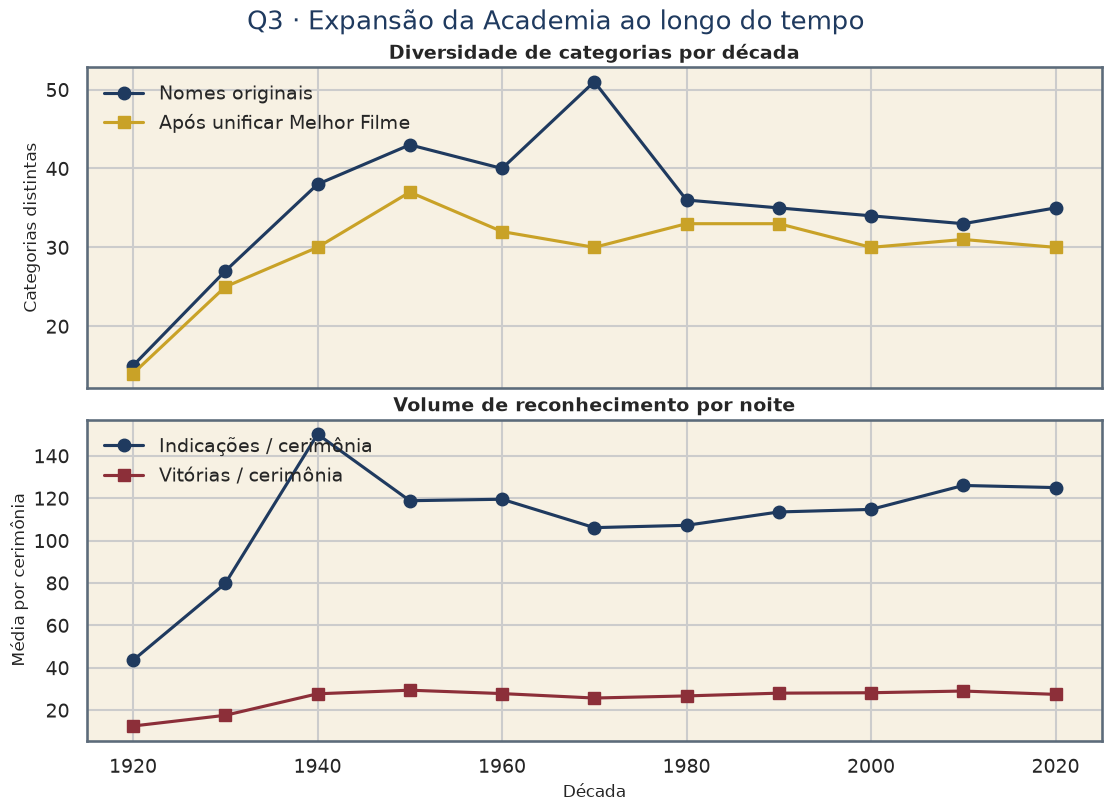

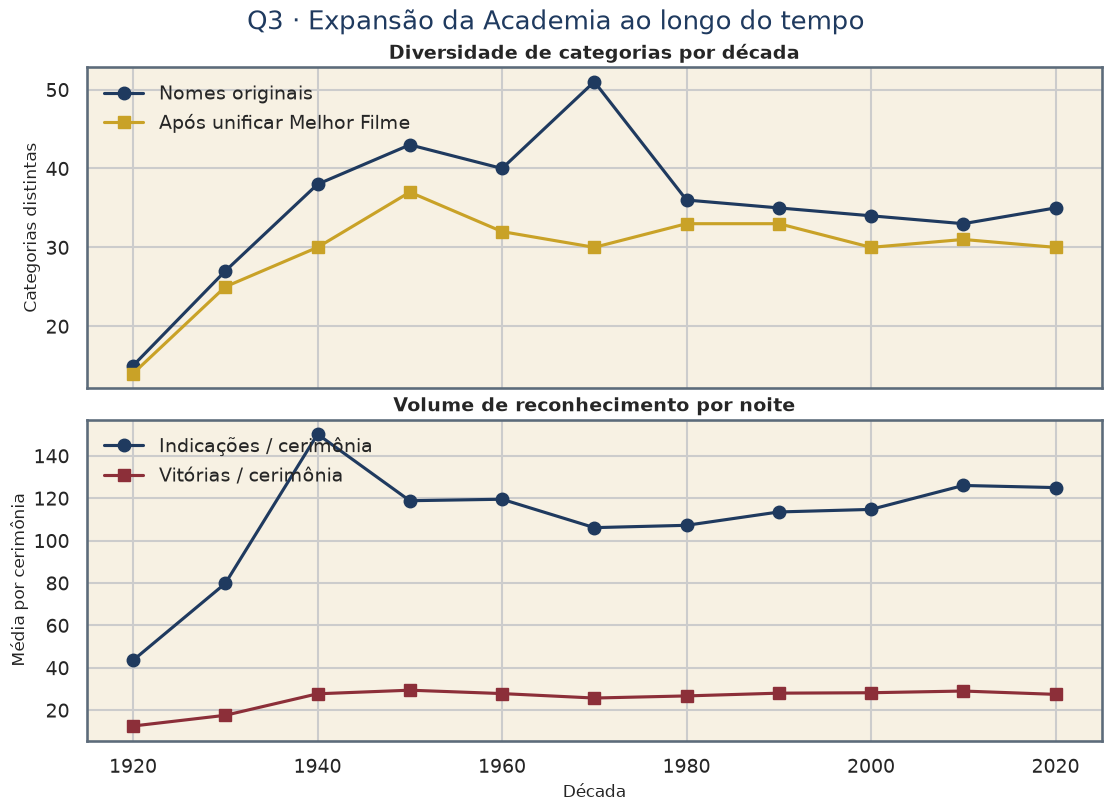

In [11]:
fig = q03_evolucao.plot(q03)
save_fig(fig, q03_evolucao.SLUG)
fig

**Insight.** A Academia do século XXI reconhece mais ofícios do que a dos anos 1930: efeitos, som, animação, documentário. Isso abre frentes de prestígio (e de campanha) que não existiam quando o prêmio era quase só filme, direção e atuação.

## Q4. Volume vs. eficiência de profissionais

Quais profissionais ou entidades possuem o maior histórico de indicações e quem tem a melhor eficiência entre os mais indicados?

Filtro: pelo menos 5 indicações competitivas, excluindo filme internacional (onde `name` é o país). Dois rankings — quem mais é chamado à festa e quem melhor converte o convite em estatueta.

In [12]:
print(q04_eficiencia.QUESTION)
q04 = q04_eficiencia.compute(df)
display(q04.head(15))
q04.sort_values(['win_rate', 'nominations'], ascending=False).head(15)

Quais profissionais ou entidades possuem o maior histórico de indicações e quem tem a melhor eficiência entre os mais indicados?


,name,nominations,wins,first_year,last_year,win_rate
0,Metro-Goldwyn-Mayer,67,12,1928,1968,0.179104
1,Walt Disney,59,22,1932,1969,0.372881
2,John Williams,47,5,1968,2024,0.106383
3,Warner Bros.,43,7,1930,1963,0.162791
4,Alfred Newman,34,7,1939,1971,0.205882
5,Paramount,25,5,1933,1952,0.200000
6,RKO Radio,24,1,1931,1948,0.041667
7,Gordon Hollingshead,23,7,1933,1953,0.304348
8,Edith Head,22,4,1952,1976,0.181818
9,20th Century-Fox,22,3,1938,1969,0.136364


,name,nominations,wins,first_year,last_year,win_rate
190,John Ford,5,4,1936,1953,0.800000
132,John Barry,6,4,1967,1993,0.666667
191,20th Century-Fox/Thomas T. Moulton,5,3,1946,1953,0.600000
192,Daniel Mandell,5,3,1942,1961,0.600000
193,James L. Brooks,5,3,1984,1988,0.600000
194,Leo McCarey,5,3,1938,1953,0.600000
195,Metro-Goldwyn-Mayer/Franklin E. Milton,5,3,1960,1967,0.600000
196,Nick Park,5,3,1991,2010,0.600000
197,Oliver Stone,5,3,1979,1992,0.600000
198,Richard King,5,3,2004,2015,0.600000


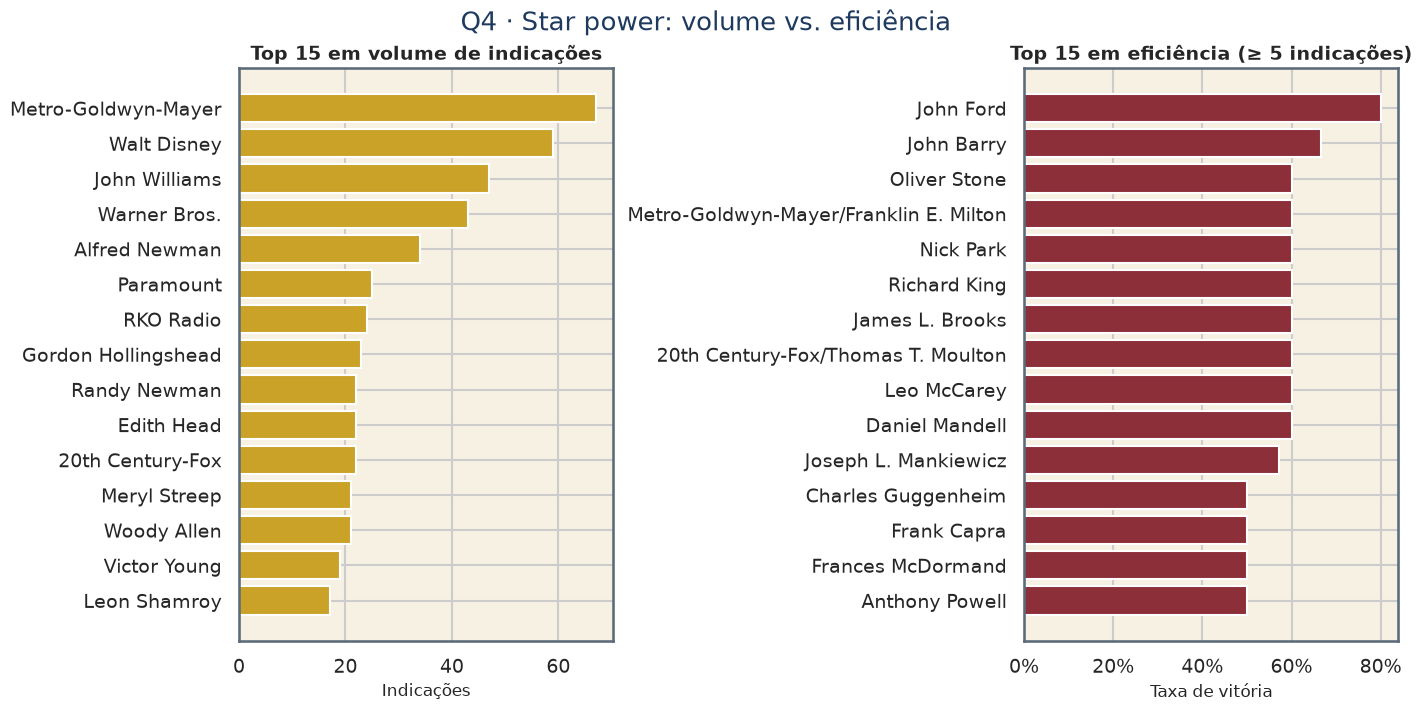

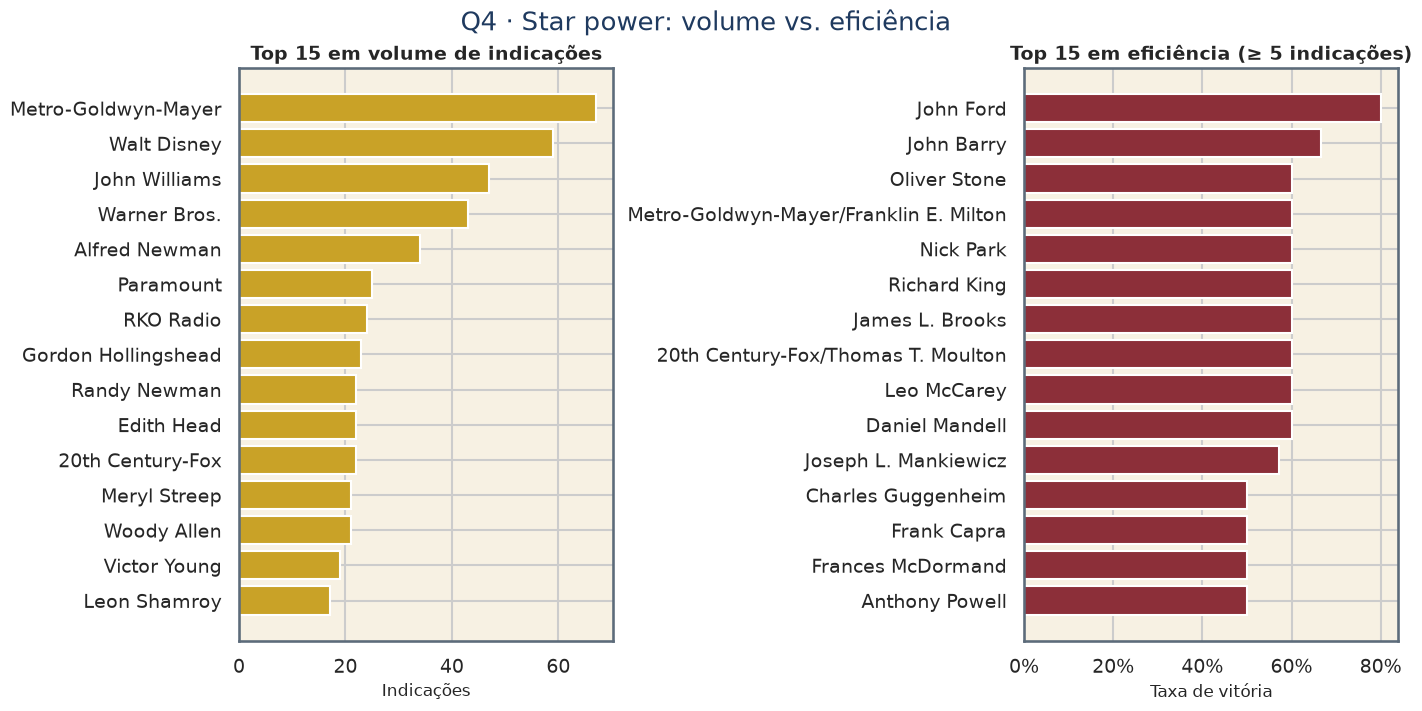

In [13]:
fig = q04_eficiencia.plot(q04)
save_fig(fig, q04_eficiencia.SLUG)
fig

**Insight.** *Star power* compra indicação com mais previsibilidade do que vitória. Contratar o profissional mais indicado aumenta a chance de entrar na cédula; a taxa de conversão dos recordistas costuma ser bem mais baixa do que o marketing de "vencedor do Oscar" sugere. Eficiência e volume não são a mesma lista.

## Q5. Concentração vs. pulverização da noite

Qual é o nível de concentração vs. democratização do Oscar ao longo do tempo: quantos filmes diferentes dividem os prêmios em uma cerimônia?

Por cerimônia: quantos filmes distintos levaram pelo menos uma estatueta competitiva, e que fração dos prêmios ficou com o filme mais premiado (efeito varredura).

In [14]:
print(q05_concentracao.QUESTION)
q05 = q05_concentracao.compute(df)
display(q05.tail(10))
from projeto1_c11.questions.q05_concentracao import decade_means
decade_means(q05)

Qual é o nível de concentração vs. democratização do Oscar ao longo do tempo: quantos filmes diferentes dividem os prêmios em uma cerimônia?


,year_ceremony,n_winning_films,n_awards,max_film_wins,top_film_share,decade,n_winning_films_ma,top_film_share_ma
88,2017,15,24,6,0.250000,2010,15.400000,0.200000
89,2018,15,24,4,0.166667,2010,15.400000,0.200000
90,2019,15,24,4,0.166667,2010,15.200000,0.176087
91,2020,16,24,4,0.166667,2020,15.200000,0.178261
92,2021,15,23,3,0.130435,2020,14.800000,0.205797
93,2022,15,23,6,0.260870,2020,14.400000,0.233333
94,2023,13,23,7,0.304348,2020,14.000000,0.243478
95,2024,13,23,7,0.304348,2020,13.800000,0.265391
96,2025,14,23,5,0.217391,2020,13.500000,0.266522
97,2026,14,25,6,0.240000,2020,13.666667,0.253913


,decade,mean_winning_films,mean_top_film_share,n_ceremonies
0,1920,8.500000,0.171429,2
1,1930,10.777778,0.232562,9
2,1940,16.200000,0.219887,10
3,1950,15.500000,0.250484,10
4,1960,14.100000,0.263940,10
5,1970,13.000000,0.266667,10
6,1980,13.100000,0.257154,10
7,1990,13.800000,0.277108,10
8,2000,14.700000,0.230978,10
9,2010,14.600000,0.207667,10


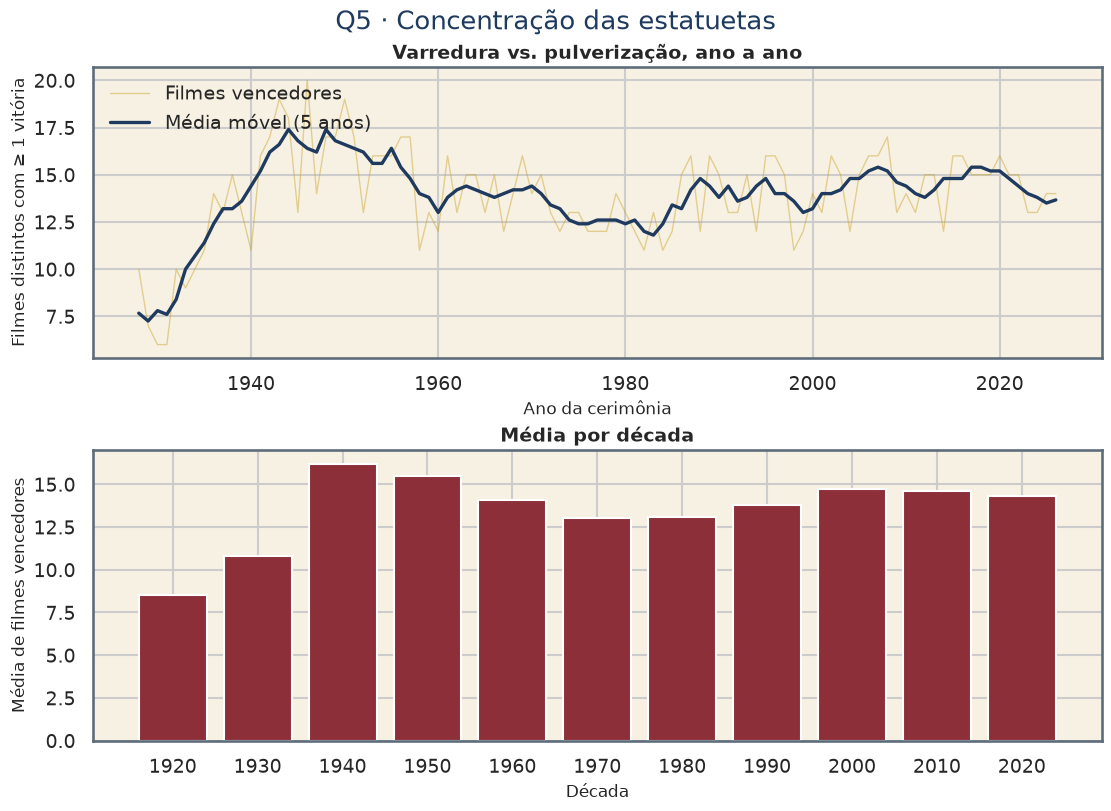

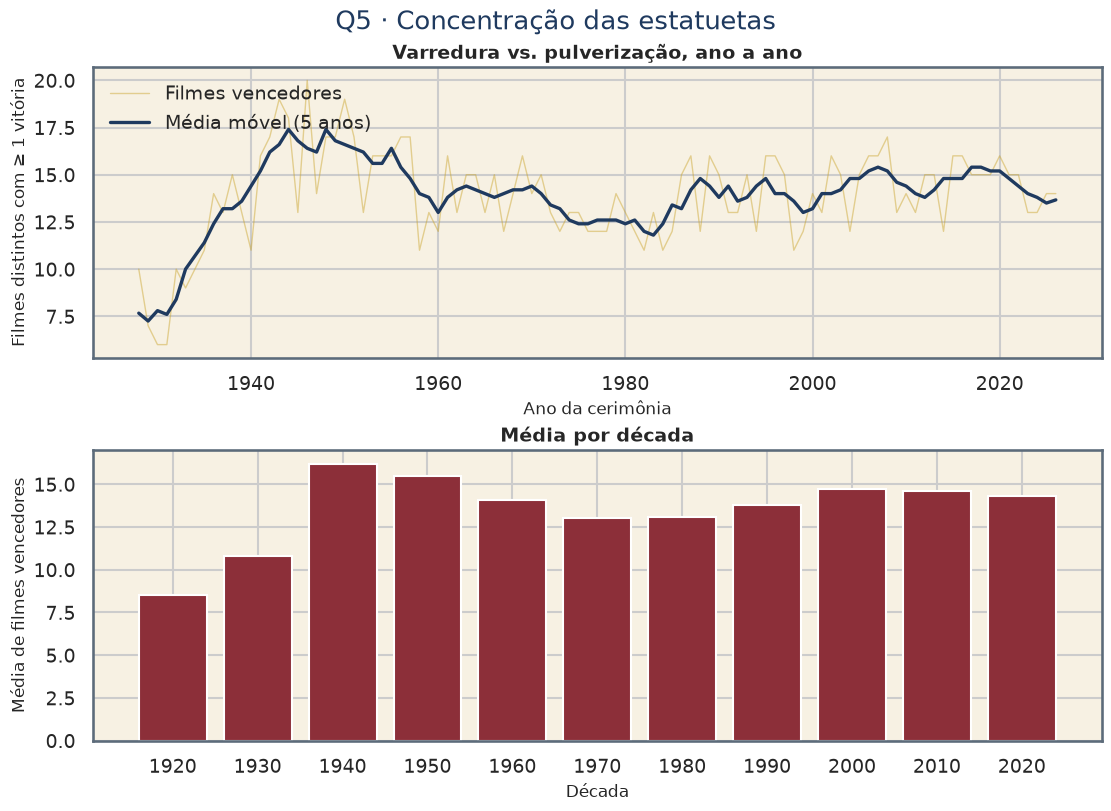

In [15]:
fig = q05_concentracao.plot(q05)
save_fig(fig, q05_concentracao.SLUG)
fig

**Insight.** Noites de varredura (um filme levando fatia grande do quadro) aumentam o risco para concorrentes: o prestígio e a narrativa da imprensa ficam monopolizados. Décadas mais pulverizadas abrem espaço para independentes e *streamings* saírem com 1–2 estatuetas e ainda assim venderem o selo Oscar.